# Transforming MATLAB files into Machine Learning Reading CSV files
A new version of this dataset has been published. This dataset explore the original raw dataset and transform it into a Machine Learning ready dataset in a significantly better format.

In [3]:
# Some boring imports
import numpy as np
import pandas as pd
import os
import scipy.io

In [ ]:
# pip install gdown

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


I will now download the contents of the Google Drive folder. I'll create a local directory called `battery_data` for this.

Now I will modify the `load_filelist` function to scan the `battery_data` directory, and then re-run the `FILELIST` generation.

In [5]:
# Helper functions
def load_filelist():

    FILELIST = []
    # The correct path to the folder in MyDrive, based on the `os.listdir` output.
    target_directory = 'C:/Users/prshi/Downloads/SOH-prediction-using-NASA-Dataset-master/SOH-prediction-using-NASA-Dataset-master/1. BatteryAgingARC-FY08Q4'

    for dirname, _, filenames in os.walk(target_directory):
        for filename in filenames:
            #filepath = filename
            FILELIST.append(os.path.join(dirname, filename))
    return FILELIST


def filter_matfiles_list(filelist):
    filelist = [filepath for filepath in filelist if filepath.endswith('.mat')]
    filelist = [filepath for filepath in filelist if "BatteryAgingARC_25_26_27_28_P1" not in filepath] # removing duplicates
    return filelist


def loadmat(filepath):
    return scipy.io.loadmat(filepath, simplify_cells=True)

In [6]:
FILELIST = filter_matfiles_list(load_filelist())

In [7]:
os.listdir('C:/Users/prshi/Downloads/SOH-prediction-using-NASA-Dataset-master/SOH-prediction-using-NASA-Dataset-master/1. BatteryAgingARC-FY08Q4')


['B0005.mat', 'B0006.mat', 'B0007.mat', 'B0018.mat', 'README.txt']

## Generic Dataset Informations
Repeated charge and discharge cycles result in accelerated aging of the batteries while impedance measurements provide insight into the internal battery parameters that change as aging progresses.

- Charge profile:
    - The charge profile for all battery tests seems to be identifical.
    - Charging was carried out in a constant current (CC) mode at 1.5A until the battery voltage reached 4.2V and then continued in a constant voltage (CV) mode until the charge current dropped to 20mA.

- Discharge:
    - Discharge profiles were different from battery to battery.
    - Discharge was carried out at a constant current (CC) level of 1-4 A until the battery voltage fell to values such 2.7V, 2.5V, 2.2V and 2.5V.

- Impedance:
    - Impedance measurement was carried out through an electrochemical impedance spectroscopy (EIS) frequency sweep from 0.1Hz to 5kHz.

The experiments were stopped when the batteries reached a given end-of-life (EOL) criteria: for example 30% fade in rated capacity (from 2Ahr to 1.4Ahr). Other stopping criteria were used such as 20% fade in rated capacity. Note that for batteries 49,50,51,52, the experiments were not stop due to battery EOL but because the software has crashed.

# Tasks

This dataset can be used for the prediction of both:
- remaining charge (for a given discharge cycle) and,
- remaining useful life (RUL).

## Structure of .mat files
- **dictionary** (loaded mat file)
    - **dictionary** (e.g. B0005)
        - **list (cycle)** -> one test per element in the list
            - element of the list = dict = all data for one test of that battery
                - **type**:  operation  type, can be charge, discharge or impedance
                - **ambient_temperature**:  ambient temperature (degree C)
                - **time**:  the date and time of the start of the cycle, in MATLAB  date vector format
                - **data (dict)**:  data structure containing the measurements
                    - data fields with key being measured variable, values the actual records (see below)
                    
                    
*    for charge the fields are:
    *     Voltage_measured: 	Battery terminal voltage (Volts)
    *     Current_measured:	Battery output current (Amps)
    *     Temperature_measured: 	Battery temperature (degree C)
    *     Current_charge:		Current measured at charger (Amps)
    *     Voltage_charge:		Voltage measured at charger (Volts)
    *     Time:			Time vector for the cycle (secs)
*    for discharge the fields are:
    *     Voltage_measured: 	Battery terminal voltage (Volts)
    *     Current_measured:	Battery output current (Amps)
    *     Temperature_measured: 	Battery temperature (degree C)
    *     Current_load:		Current measured at load (Amps)
    *     Voltage_load:		Voltage measured at load (Volts)
    *     Time:			Time vector for the cycle (secs)
    *     Capacity:		Battery capacity (Ahr) for discharge till 2.7V
*    for impedance the fields are:
    *     Sense_current:		Current in sense branch (Amps)
    *     Battery_current:	Current in battery branch (Amps)
    *     Current_ratio:		Ratio of the above currents
    *     Battery_impedance:	Battery impedance (Ohms) computed from raw data
    *     Rectified_impedance:	Calibrated and smoothed battery impedance (Ohms)
    *     Re:			Estimated electrolyte resistance (Ohms)
    *     Rct:			Estimated charge transfer resistance (Ohms)

### Differences between README files
- discharge CC level
- discharge runs stopped voltage
- EOL criteria (30% -> 1.4 Ah, 20% -> 1.6 Ah, software crash)

In [9]:
mat = loadmat(next(path for path in FILELIST if os.path.basename(path) == 'B0005.mat'))
df = pd.DataFrame(data=mat['B0005']['cycle'][0]['data'])

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 789 entries, 0 to 788
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Voltage_measured      789 non-null    float64
 1   Current_measured      789 non-null    float64
 2   Temperature_measured  789 non-null    float64
 3   Current_charge        789 non-null    float64
 4   Voltage_charge        789 non-null    float64
 5   Time                  789 non-null    float64
dtypes: float64(6)
memory usage: 37.1 KB


In [12]:
import matplotlib.pyplot as plt

def plot_test_data(df, profile="charge"):

    if profile=='charge':
        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Voltage_measured, 'b', label='Voltage_measured')
        plt.plot(df.Time, df.Current_measured, 'r', label='Current_measured')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Voltage_charge, 'b', label='Voltage_charge')
        plt.plot(df.Time, df.Current_charge, 'r', label='Current_charge')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Temperature_measured, 'k', label='Temperature_measured')
        plt.legend()
        plt.show()
    elif profile=='discharge':
        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Voltage_measured, 'b', label='Voltage_measured')
        plt.plot(df.Time, df.Current_measured, 'r', label='Current_measured')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Voltage_load, 'b', label='Voltage_load')
        plt.plot(df.Time, df.Current_load, 'r', label='Current_load')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10,4))
        plt.plot(df.Time, df.Temperature_measured, 'k', label='Temperature_measured')
        plt.legend()
        plt.show()
    elif profile=='impedance':
        pass
    else:
        print('No cycle recognized')

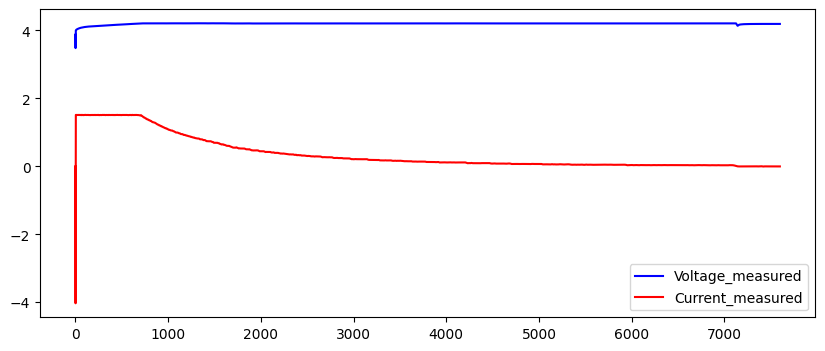

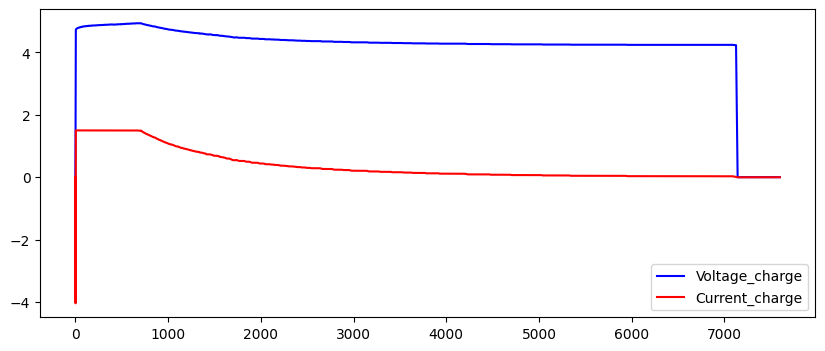

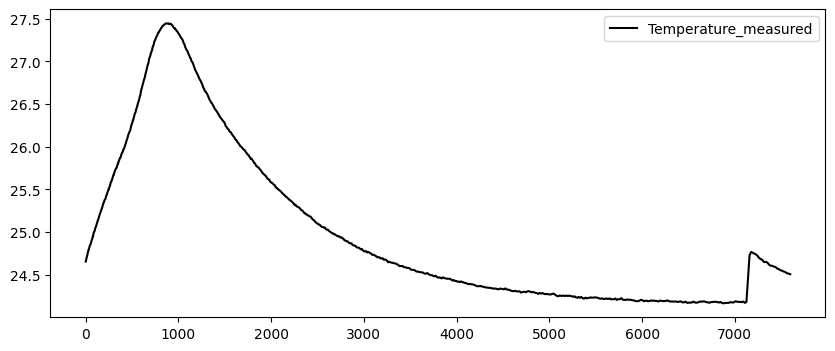

In [ ]:
plot_test_data(df)

In [13]:
df = pd.DataFrame(data=mat['B0005']['cycle'][1]['data'])
df.head()

,Voltage_measured,Current_measured,Temperature_measured,Current_load,Voltage_load,Time,Capacity
0,4.191492,-0.004902,24.330034,-0.0006,0.000,0.000,1.856487
1,4.190749,-0.001478,24.325993,-0.0006,4.206,16.781,1.856487
2,3.974871,-2.012528,24.389085,-1.9982,3.062,35.703,1.856487
3,3.951717,-2.013979,24.544752,-1.9982,3.030,53.781,1.856487
4,3.934352,-2.011144,24.731385,-1.9982,3.011,71.922,1.856487


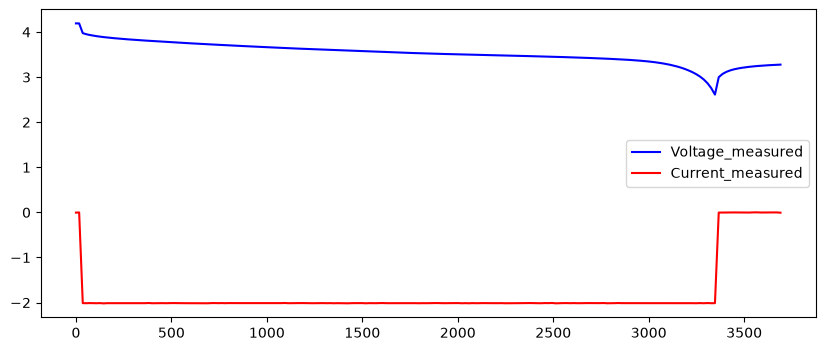

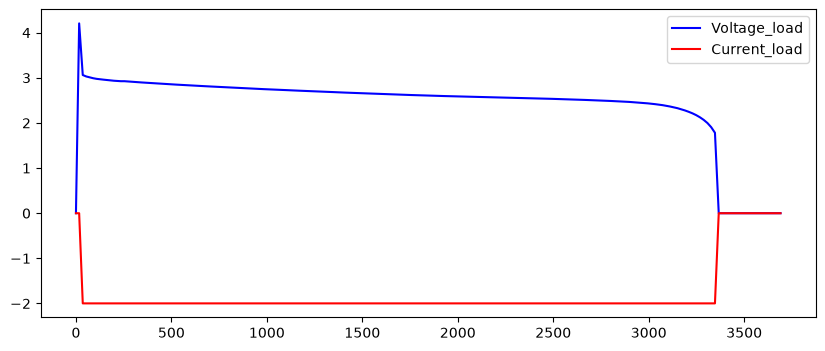

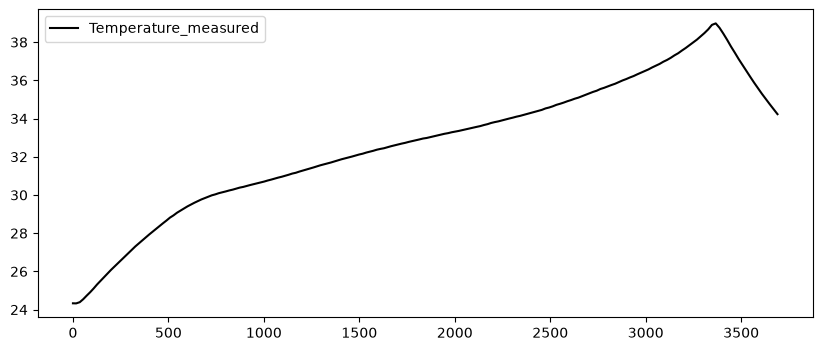

In [14]:
plot_test_data(df, profile='discharge')

In [15]:
def process_data_dict(data_dict):
    """ Creates two dictionaries:
    - ndict: new dictionary with the test data to build a corresponding dataframe
    - metadata_dict: anything that doesn't fit in ndict ('Capacity' is just a float)
    """

    ndict = {}
    metadata_dict = {}
    for k, v in data_dict.items():
        if k not in ['Capacity', 'Re', 'Rct']:
            ndict[k]=v
        elif k == 'Capacity':
            metadata_dict[k]=v
        elif k == 'Re':
            metadata_dict[k]=v
        elif k == 'Rct':
            metadata_dict[k]=v
        else:
            print("c'est la merde")

    return ndict, metadata_dict


def fill_metadata_row(metadata, test_type, test_start_time, test_temperature, battery_name, test_id, uid, filename, capacity, re, rct):
    tmp = pd.DataFrame(data=[test_type, test_start_time, test_temperature, battery_name, test_id, uid, filename, capacity, re, rct])
    tmp = tmp.transpose()
    tmp.columns = metadata.columns
    metadata = pd.concat((metadata, tmp), axis=0)
    return metadata


def extract_more_metadata(metadata_dict):

    if 'Capacity' in metadata_dict.keys():
        capacity = metadata_dict['Capacity']
    else:
        capacity = np.nan

    if 'Re' in metadata_dict.keys():
        re = metadata_dict['Re']
    else:
        re = np.nan

    if 'Rct' in metadata_dict.keys():
        rct = metadata_dict['Rct']
    else:
        rct = np.nan

    return capacity, re, rct

In [20]:
metadata = pd.DataFrame(data=None, columns=['type', 'start_time', 'ambient_temperature', 'battery_id', 'test_id', 'uid', 'filename', 'Capacity', 'Re', 'Rct'])
battery_list = [os.path.splitext(os.path.basename(item))[0] for item in FILELIST]

In [21]:
# We create a tmp directory in which we will save all CSV files
CWD = os.getcwd()
os.listdir(CWD)
directory = "tmp"
path = os.path.join(CWD, directory)
if not os.path.exists(path):
    os.mkdir(path)

In [22]:
os.listdir(CWD) # we check that tmp exists now

['.venv',
 '1. BatteryAgingARC-FY08Q4',
 'B0005.mat',
 'B0006.mat',
 'B0007.mat',
 'B0018.mat',
 'DataAnalysis.ipynb',
 'mat2json.py',
 'metadata.csv',
 'nasa_battery_life_prediction_dataset_cleaning.ipynb',
 'README.md',
 'SVM.py',
 'tmp',
 'util.py',
 '__pycache__']

In [23]:
uid = 0
# counter = 0
for battery_name, mat_filepath in zip(battery_list, FILELIST):
    # counter +=1

    mat_data = scipy.io.loadmat(mat_filepath, simplify_cells=True)
    print(mat_filepath[-10:],"-->", battery_name)
    test_list = mat_data[battery_name]['cycle']

    for test_id in range(len(test_list)):

        uid += 1
        filename = str(uid).zfill(5)+'.csv'
        filepath = './tmp/' + filename

        # Extract the specific test data and save it as CSV!
        ndict, metadata_dict = process_data_dict(test_list[test_id]['data'])
        test_df = pd.DataFrame.from_dict(ndict, orient='index')
        test_df = test_df.transpose()

        test_df.to_csv(filepath, index=False)

        # Add test information to the metadata
        test_type = test_list[test_id]['type']
        test_start_time = test_list[test_id]['time']
        test_temperature = test_list[test_id]['ambient_temperature']

        capacity, re, rct = extract_more_metadata(metadata_dict)
        metadata = fill_metadata_row(metadata, test_type, test_start_time, test_temperature, battery_name, test_id, uid, filename, capacity, re, rct)

    # if counter > 2:
    #    break

\B0005.mat --> B0005
\B0006.mat --> B0006
\B0007.mat --> B0007
\B0018.mat --> B0018


In [24]:
metadata.to_csv('metadata.csv', index=False)

In [25]:
metadata.info()

<class 'pandas.DataFrame'>
Index: 2167 entries, 0 to 0
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   type                 2167 non-null   object
 1   start_time           2167 non-null   object
 2   ambient_temperature  2167 non-null   object
 3   battery_id           2167 non-null   object
 4   test_id              2167 non-null   object
 5   uid                  2167 non-null   object
 6   filename             2167 non-null   object
 7   Capacity             636 non-null    object
 8   Re                   887 non-null    object
 9   Rct                  887 non-null    object
dtypes: object(10)
memory usage: 186.2+ KB
